# SafeRoute crime-risk model: explore, train, infer

This notebook walks through the whole risk model end to end:

1. **Explore** the LAPD incidents we downloaded within 10 miles of USC (`data/crime.db`)
2. **Train** the XGBoost cell × hour model (and the sklearn comparison) with a time-based split
3. **Evaluate** it on the full 2023 grid, with calibration and SHAP
4. **Infer** with `score_cell` / `explain_cell`, the same functions the Flask API calls

It reuses the code in `algorithm/`, so anything you change in the scripts shows up here.
Run it from the `algorithm/` folder with **Kernel → Restart & Run All**. It takes about 3–4 minutes and ~2 GB of RAM.

In [1]:
import sys, sqlite3, datetime as dt
from pathlib import Path

# Make `import algorithm...` work whether the kernel starts in algorithm/ or the repo root.
here = Path.cwd().resolve()
repo_root = here.parent if here.name == "algorithm" else here
sys.path.insert(0, str(repo_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
import h3

from algorithm.common import config, geo
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("repo root:", repo_root)
print("database :", config.DB_PATH)

repo root: /home/user/repo
database : /home/user/repo/algorithm/data/crime.db


## 1. Data

If `data/crime.db` is missing, this cell downloads it from the LA Open Data API (about a minute).

In [2]:
if not config.DB_PATH.exists():
    from algorithm.data import ingest_crime
    ingest_crime.main()

con = sqlite3.connect(config.DB_PATH)
inc = pd.read_sql("SELECT * FROM incidents", con, parse_dates=["date_occ"])
con.close()
inc["year"] = inc.date_occ.dt.year
inc["weekday"] = inc.date_occ.dt.day_of_week
print(f"{len(inc):,} incidents  |  {inc.date_occ.min():%Y-%m-%d} to {inc.date_occ.max():%Y-%m-%d}  |  {inc.cell.nunique()} H3 cells")
inc.head()

647,921 incidents  |  2020-01-01 to 2024-12-30  |  3722 H3 cells


,dr_no,date_occ,time_occ,hour,lat,lon,crm_cd,crm_cd_desc,weapon_used_cd,part_1_2,cell,tier,year,weekday
0,010304468,2020-01-08,2230,22,34.0141,-118.2978,624,BATTERY - SIMPLE ASSAULT,400,2,8929a1d648fffff,violent,2020,2
1,190101086,2020-01-01,330,3,34.0459,-118.2545,624,BATTERY - SIMPLE ASSAULT,500,2,8929a1d75afffff,violent,2020,2
2,190101087,2020-01-01,510,5,34.0447,-118.2452,626,INTIMATE PARTNER - SIMPLE ASSAULT,400,2,8929a1d7503ffff,violent,2020,2
3,190326475,2020-03-01,2130,21,34.0375,-118.3506,510,VEHICLE - STOLEN,NaN,1,8929a1992a3ffff,property,2020,6
4,200100001,2020-02-25,2000,20,34.0617,-118.2469,510,VEHICLE - STOLEN,NaN,1,8929a1d718fffff,property,2020,1


### Volume over time

Note the drop from March 2024: that is LAPD's switch to NIBRS reporting, not a real fall in crime. It's why we train on 2020–2022 and test on 2023.

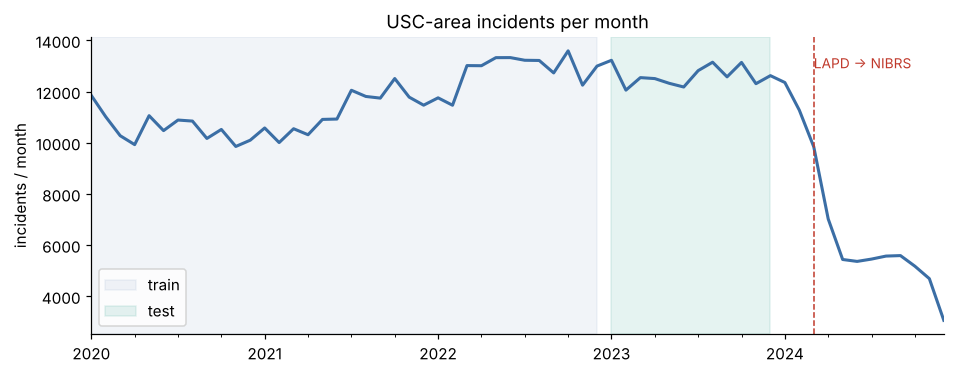

year,2020,2021,2022,2023,2024
incidents,126997,134671,153926,151463,80864


In [3]:
monthly = inc.set_index("date_occ").resample("MS").size()
fig, ax = plt.subplots(figsize=(10, 3.5))
monthly.plot(ax=ax, color="#3b6ea5", lw=2)
ax.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2022-12-31"), color="#3b6ea5", alpha=0.07, label="train")
ax.axvspan(pd.Timestamp("2023-01-01"), pd.Timestamp("2023-12-31"), color="#2a9d8f", alpha=0.12, label="test")
ax.axvline(pd.Timestamp("2024-03-01"), color="#c0392b", ls="--", lw=1)
ax.text(pd.Timestamp("2024-03-15"), monthly.max() * 0.95, "LAPD → NIBRS", color="#c0392b", fontsize=9)
ax.set_ylabel("incidents / month"); ax.set_xlabel(""); ax.legend(loc="lower left")
ax.set_title("USC-area incidents per month")
plt.show()
inc.groupby("year").size().rename("incidents").to_frame().T

### Severity mix and most common crimes

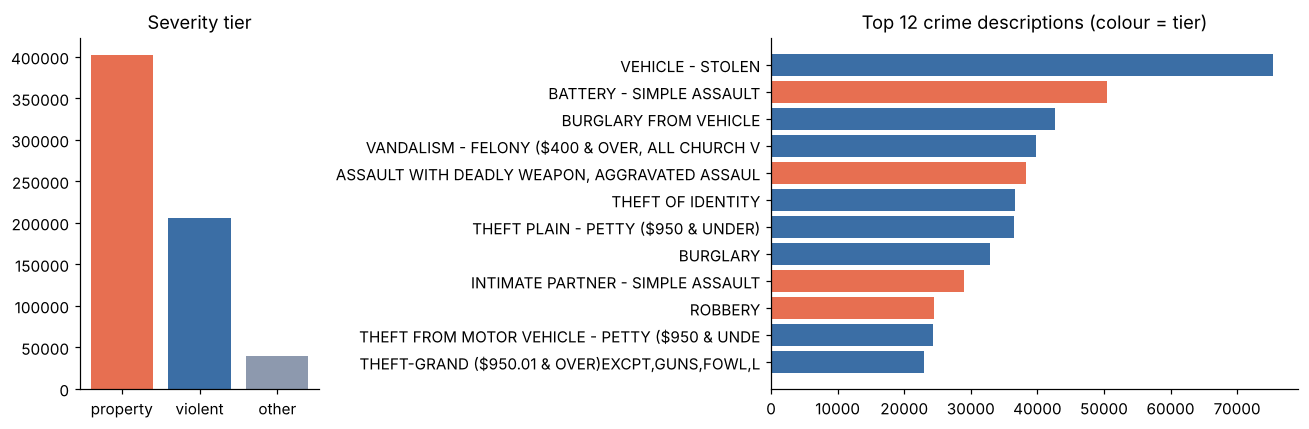

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 2.2]})
tier = inc.tier.value_counts()
axes[0].bar(tier.index, tier.values, color=["#e76f51", "#3b6ea5", "#8d99ae"])
axes[0].set_title("Severity tier")
top = inc.crm_cd_desc.value_counts().head(12)[::-1]
colors = inc.drop_duplicates("crm_cd_desc").set_index("crm_cd_desc").loc[top.index, "tier"].map(
    {"violent": "#e76f51", "property": "#3b6ea5", "other": "#8d99ae"})
axes[1].barh([s[:45] for s in top.index], top.values, color=colors)
axes[1].set_title("Top 12 crime descriptions (colour = tier)")
plt.tight_layout(); plt.show()

### When does it happen?

The spike at noon is partly an artifact: LAPD records `time_occ = 1200` when the time is unknown.

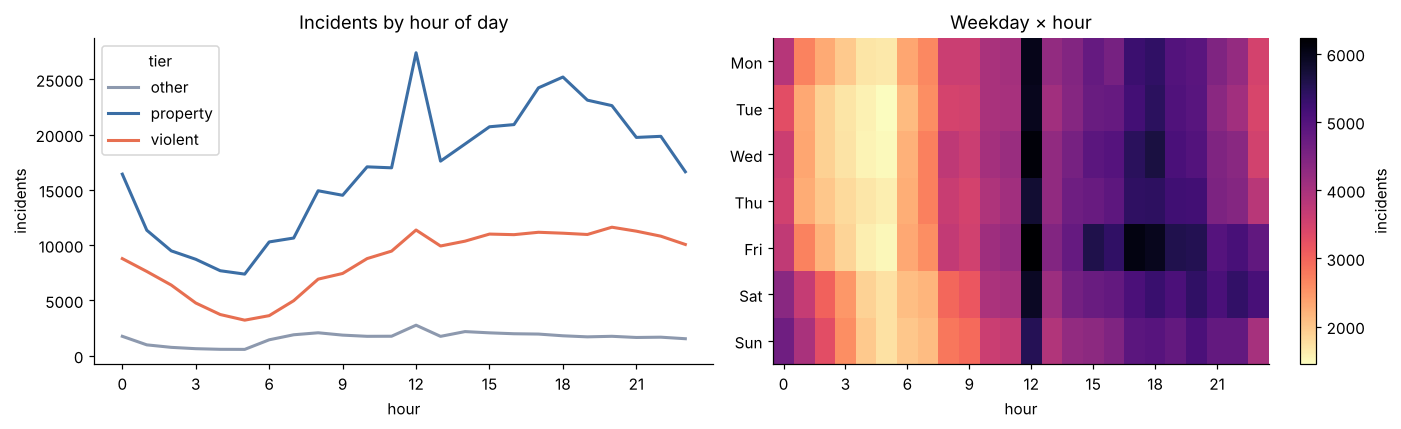

share at exactly 12:00: 3.1%


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
by_hour = inc.groupby(["hour", "tier"]).size().unstack(fill_value=0)
by_hour.plot(ax=axes[0], color={"violent": "#e76f51", "property": "#3b6ea5", "other": "#8d99ae"}, lw=2)
axes[0].set_xticks(range(0, 24, 3)); axes[0].set_title("Incidents by hour of day"); axes[0].set_ylabel("incidents")

grid = inc.groupby(["weekday", "hour"]).size().unstack(fill_value=0)
im = axes[1].imshow(grid, aspect="auto", cmap="magma_r")
axes[1].set_yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axes[1].set_xticks(range(0, 24, 3)); axes[1].set_xlabel("hour"); axes[1].set_title("Weekday × hour")
plt.colorbar(im, ax=axes[1], label="incidents")
plt.tight_layout(); plt.show()
print("share at exactly 12:00:", f"{(inc.time_occ == 1200).mean():.1%}")

### After dark

We compute civil dawn/dusk for LA on each date with `astral`.

In [6]:
inc["is_dark"] = [geo.is_dark(d.date(), h) for d, h in zip(inc.date_occ, inc.hour)]
days = pd.date_range(config.DATA_START, config.DATA_END)
dark_hours = np.mean([geo.is_dark(d.date(), h) for d in days[::7] for h in range(24)])
pd.DataFrame({
    "share of all hours that are dark": [dark_hours],
    "share of incidents after dark": [inc.is_dark.mean()],
    "share of VIOLENT incidents after dark": [inc.loc[inc.tier == "violent", "is_dark"].mean()],
}).T.rename(columns={0: "value"}).style.format("{:.1%}")

,value
share of all hours that are dark,45.2%
share of incidents after dark,41.0%
share of VIOLENT incidents after dark,42.9%


### Where? Incidents per H3 cell (res 9, ~175 m)

Blue dots are the **placeholder** blue-light phone points from `common/geo.py`.

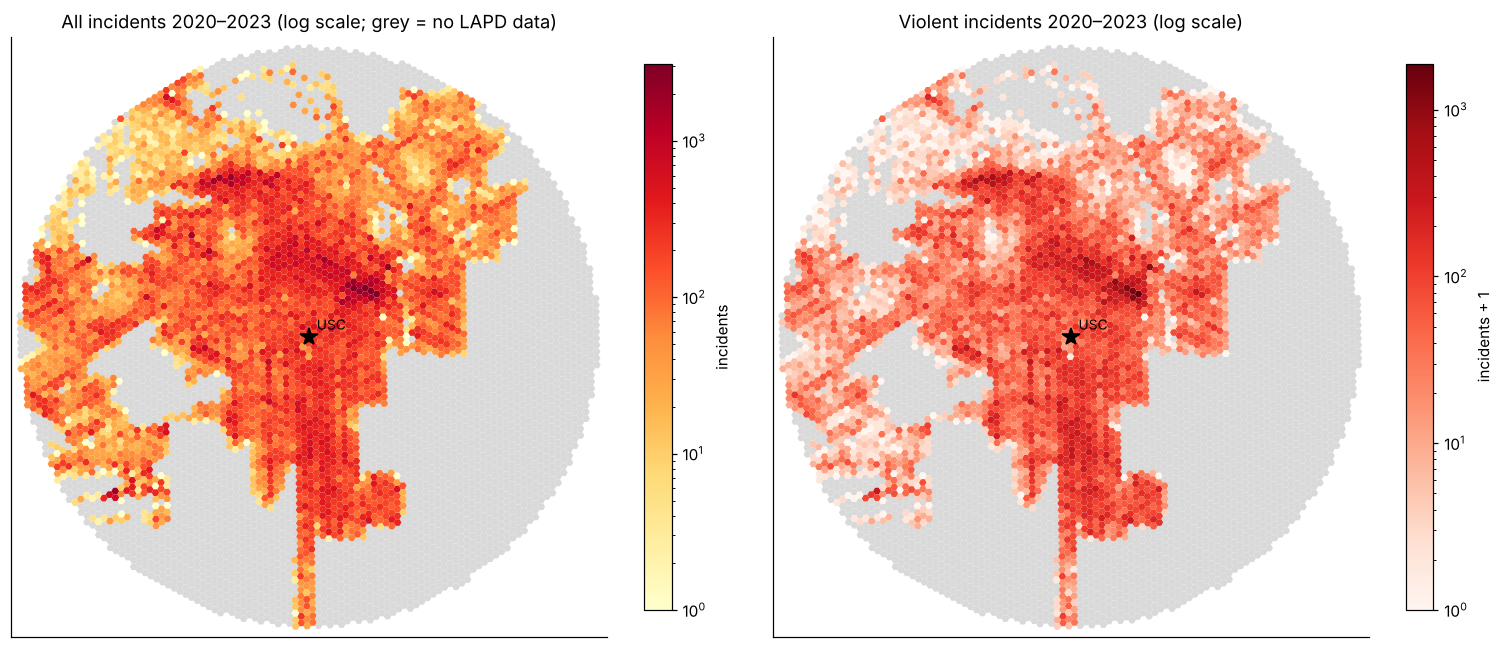

6,898 H3 cells within 10 miles; 3,686 have LAPD incidents, 3,212 have none (mostly other police jurisdictions: Inglewood, Culver City, Beverly Hills, Vernon, county areas)


In [7]:
def hexmap(ax, values: dict, title, cmap="YlOrRd", vmin=None, vmax=None, label="", no_data=()):
    """Draw H3 cells coloured by value; `no_data` cells in grey."""
    if no_data:
        ax.add_collection(PolyCollection([[(lng, lat) for lat, lng in h3.cell_to_boundary(c)] for c in no_data],
                                         facecolor="#d9d9d9", edgecolor="none"))
    cells = list(values)
    polys = [[(lng, lat) for lat, lng in h3.cell_to_boundary(c)] for c in cells]
    pc = PolyCollection(polys, array=np.array([values[c] for c in cells], dtype=float),
                        cmap=cmap, edgecolor="none")
    if vmin is not None: pc.set_clim(vmin, vmax)
    ax.add_collection(pc)
    s, w, n, e = config.BBOX
    ax.set_xlim(w - 0.005, e + 0.005); ax.set_ylim(s - 0.005, n + 0.005)
    ax.set_aspect(1 / np.cos(np.radians(config.CENTER[0])))
    ax.plot(config.CENTER[1], config.CENTER[0], marker="*", color="black", ms=12)
    ax.annotate("USC", (config.CENTER[1], config.CENTER[0]), xytext=(5, 5), textcoords="offset points", fontsize=9)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(pc, ax=ax, shrink=0.8, label=label)

from matplotlib.colors import LogNorm
area_cells = geo.area_cells()
counts = inc[inc.year <= 2023].groupby("cell").size()
violent = inc[(inc.year <= 2023) & (inc.tier == "violent")].groupby("cell").size()
has = [c for c in area_cells if counts.get(c, 0) > 0]
empty = [c for c in area_cells if counts.get(c, 0) == 0]
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
hexmap(axes[0], {c: counts[c] for c in has}, "All incidents 2020–2023 (log scale; grey = no LAPD data)", label="incidents", no_data=empty)
axes[0].collections[-1].set_norm(LogNorm(1, counts.max()))
hexmap(axes[1], {c: violent.get(c, 0) + 1 for c in has}, "Violent incidents 2020–2023 (log scale)", cmap="Reds", label="incidents + 1", no_data=empty)
axes[1].collections[-1].set_norm(LogNorm(1, violent.max() + 1))
plt.tight_layout(); plt.show()
print(f"{len(area_cells):,} H3 cells within {config.RADIUS_MILES:g} miles; {len(has):,} have LAPD incidents, "
      f"{len(empty):,} have none (mostly other police jurisdictions: Inglewood, Culver City, Beverly Hills, Vernon, county areas)")

## 2. Build the training frame

Each row is one **(H3 cell, date, hour)**. Target = at least one incident in that cell in that hour.
All history features use only incidents from **before** the row's date, so nothing leaks from the future.
Training keeps every positive plus 15 random negatives each. We undo that sampling later (prior correction) so the outputs are real probabilities.

In [8]:
from algorithm.features.build_dataset import History, FEATURES

hist = History()
frame, neg_rate, base_rate = hist.training_frame(kind="any")
vday = hist.day_index(dt.date.fromisoformat(config.VALID_START))
tr, va = frame[frame.day < vday], frame[frame.day >= vday]
print(f"modelled cells: {len(hist.cells):,} (≥{config.MIN_CELL_INCIDENTS} incidents in training years); no-data cells: {len(hist.no_data_cells):,}")
print(f"training frame: {len(frame):,} rows, {int(frame.y.sum()):,} positives")
print(f"true base rate: {base_rate:.3%} of cell-hours have an incident; negatives kept at rate {neg_rate:.4f}")
print(f"train {len(tr):,} rows (to {config.VALID_START}), early-stopping slice {len(va):,} rows")
frame[FEATURES + ["y"]].sample(5, random_state=0)

modelled cells: 3,432 (≥5 incidents in training years); no-data cells: 3,466
training frame: 2,167,860 rows, 361,310 positives
true base rate: 0.436% of cell-hours have an incident; negatives kept at rate 0.0219
train 1,763,393 rows (to 2022-07-01), early-stopping slice 404,467 rows


,hour,weekday,month,season,is_weekend,is_dark,cell_lat,cell_lon,dist_bluelight_m,cell_7d,...,cell_sev_90d,cell_violent_90d,cell_hourband_365d,cell_rate_all,cell_hourband_rate_all,nb1_30d,nb2_30d,nb1_90d,area_7d,y
2151169,3.0,5.0,12.0,0.0,1.0,1.0,34.055679,-118.383194,9468.704102,2.0,...,9.800011,7.0,4.0,67.766541,4.800000,20.0,44.0,62.0,2773.0,0
265925,22.0,0.0,8.0,2.0,0.0,1.0,34.017521,-118.288902,183.623032,0.0,...,0.000000,0.0,1.0,3.395349,1.714286,19.0,35.0,65.0,2524.0,0
2136083,6.0,5.0,12.0,0.0,1.0,0.0,33.956314,-118.381241,10867.835938,0.0,...,12.000031,2.0,2.0,75.971321,3.428571,23.0,11.0,47.0,2815.0,0
1661085,17.0,6.0,5.0,1.0,1.0,0.0,34.112152,-118.235184,10686.053711,2.0,...,1.200005,0.0,5.0,25.739885,5.571429,8.0,30.0,20.0,2873.0,0
2063695,19.0,0.0,11.0,3.0,0.0,1.0,33.949448,-118.388031,11838.860352,0.0,...,1.000000,1.0,0.0,1.741412,0.352941,26.0,42.0,94.0,2712.0,0


In [9]:
frame.groupby("y")[["cell_30d", "cell_hourband_365d", "cell_rate_all", "nb1_30d", "is_dark", "dist_bluelight_m"]].mean().T.rename(
    columns={0: "no incident", 1: "incident"}).round(2)

y,no incident,incident
cell_30d,3.280000,8.930000
cell_hourband_365d,4.300000,12.680000
cell_rate_all,37.740002,93.459999
nb1_30d,19.040001,38.389999
is_dark,0.450000,0.410000
dist_bluelight_m,8561.849609,6841.149902


## 3. Train

XGBoost with early stopping (same settings as `models/train_xgb.py`), and sklearn's `GradientBoostingClassifier` for comparison.

XGBoost: best iteration 1291, 129.8s


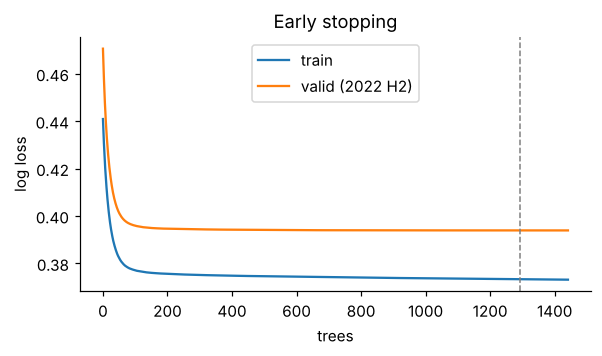

sklearn GBC: 29.0s on 80,000 rows


In [10]:
import time
import xgboost as xgb
from sklearn.ensemble import GradientBoostingClassifier

t0 = time.time()
model = xgb.XGBClassifier(
    n_estimators=2000, learning_rate=0.03, max_depth=4, min_child_weight=20,
    subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, tree_method="hist",
    eval_metric="logloss", early_stopping_rounds=150, random_state=config.SEED, n_jobs=-1)
model.fit(tr[FEATURES], tr.y, eval_set=[(tr[FEATURES], tr.y), (va[FEATURES], va.y)], verbose=False)
print(f"XGBoost: best iteration {model.best_iteration}, {time.time() - t0:.1f}s")

ev = model.evals_result()
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(ev["validation_0"]["logloss"], label="train"); ax.plot(ev["validation_1"]["logloss"], label="valid (2022 H2)")
ax.axvline(model.best_iteration, color="gray", ls="--", lw=1); ax.set_xlabel("trees"); ax.set_ylabel("log loss"); ax.legend()
ax.set_title("Early stopping"); plt.show()

t1 = time.time()
sub = tr.sample(n=min(len(tr), 80_000), random_state=config.SEED)  # GBC is single-threaded, so subsample
gbc = GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.1, subsample=0.8, random_state=config.SEED)
gbc.fit(sub[FEATURES], sub.y)
print(f"sklearn GBC: {time.time() - t1:.1f}s on {len(sub):,} rows")

## 4. Evaluate on 2023

The full 2023 grid is ~30M cell-hours, too big to score in a notebook. So the evaluation frame keeps **every** 2023 cell-hour with an incident plus a random sample of the rest, and each sampled negative carries a weight `w` = 1 / sample rate. Every metric below uses those weights, so it equals the full-grid number in expectation.

In [11]:
from sklearn.metrics import roc_curve, precision_recall_curve
from algorithm.models.train_xgb import prior_correct, evaluate, calibration_bins
# train_xgb switches matplotlib to a file backend on import; switch back to inline
%matplotlib inline

test, _, _ = hist.eval_frame(config.TEST_START, config.TEST_END)
y, w = test.y.to_numpy(), test.w.to_numpy()
p_xgb = prior_correct(model.predict_proba(test[FEATURES])[:, 1], neg_rate)
p_gbc = prior_correct(gbc.predict_proba(test[FEATURES])[:, 1], neg_rate)
p_base = test.cell_hourband_365d.to_numpy() + 1e-3 * test.cell_90d.to_numpy()
print(f"{w.sum():,.0f} cell-hours on the 2023 grid, {int(y.sum()):,} with an incident (scored {len(test):,} rows)\n")
results = pd.DataFrame({
    "XGBoost": evaluate(y, p_xgb, "XGBoost", w),
    "sklearn GBC": evaluate(y, p_gbc, "sklearn GradientBoosting", w),
    "Baseline (past-year count)": evaluate(y, p_base, "Baseline (past-year count)", w, probabilistic=False),
}).T[["auc", "pr_auc", "top10pct_capture", "brier", "mean_pred", "base_rate"]]
results.style.format("{:.4f}", na_rep="–")

30,064,320 cell-hours on the 2023 grid, 142,201 with an incident (scored 1,564,211 rows)



  XGBoost                      AUC 0.785  PR-AUC 0.0273  (base 0.0047)  top-10% capture 41.5%


  sklearn GradientBoosting     AUC 0.783  PR-AUC 0.0235  (base 0.0047)  top-10% capture 40.9%


  Baseline (past-year count)   AUC 0.772  PR-AUC 0.0261  (base 0.0047)  top-10% capture 40.4%


,auc,pr_auc,top10pct_capture,brier,mean_pred,base_rate
XGBoost,0.7855,0.0273,0.4152,0.0047,0.0051,0.0047
sklearn GBC,0.7826,0.0235,0.4091,0.0047,0.0050,0.0047
Baseline (past-year count),0.7723,0.0261,0.4039,–,–,0.0047


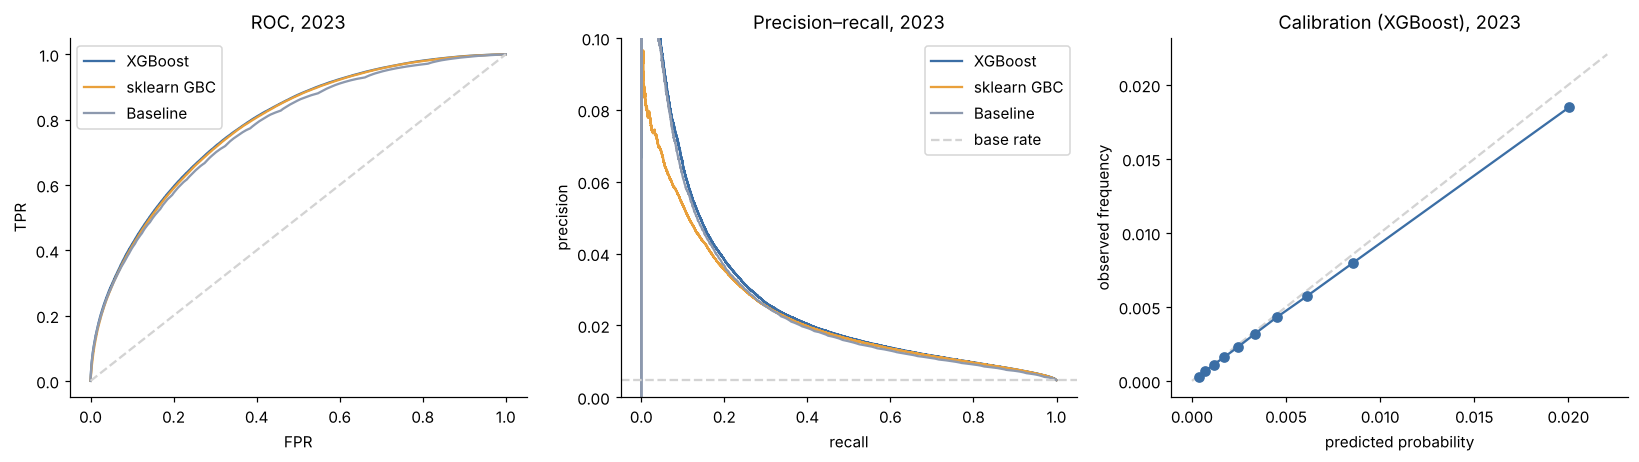

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for name, p, c in [("XGBoost", p_xgb, "#3b6ea5"), ("sklearn GBC", p_gbc, "#e9a03b"), ("Baseline", p_base, "#8d99ae")]:
    fpr, tpr, _ = roc_curve(y, p, sample_weight=w); axes[0].plot(fpr, tpr, label=name, color=c)
    pr, rc, _ = precision_recall_curve(y, p, sample_weight=w); axes[1].plot(rc, pr, label=name, color=c)
axes[0].plot([0, 1], [0, 1], ls="--", c="lightgray"); axes[0].set(title="ROC, 2023", xlabel="FPR", ylabel="TPR"); axes[0].legend()
axes[1].axhline(np.average(y, weights=w), ls="--", c="lightgray", label="base rate")
axes[1].set(title="Precision–recall, 2023", xlabel="recall", ylabel="precision", ylim=(0, 0.1)); axes[1].legend()
mean_pred, frac = calibration_bins(y, p_xgb, w)
hi = max(max(frac), max(mean_pred)) * 1.1
axes[2].plot([0, hi], [0, hi], ls="--", c="lightgray"); axes[2].plot(mean_pred, frac, marker="o", color="#3b6ea5")
axes[2].set(title="Calibration (XGBoost), 2023", xlabel="predicted probability", ylabel="observed frequency")
plt.tight_layout(); plt.show()

### Heatmap-level check

The app shows risk per cell per hour of day. Averaged over 2023, does the model's ranking of those slots match what happened?

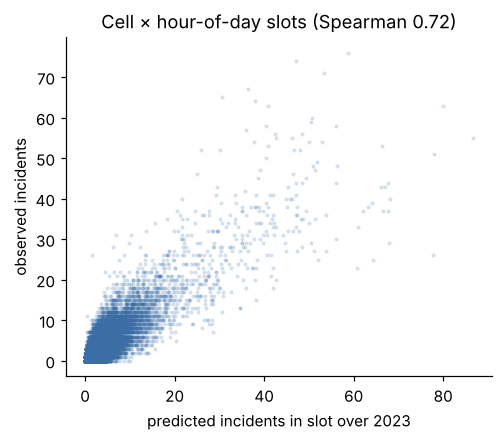

In [13]:
slot = pd.DataFrame({"cell": test.cell_idx, "hour": test.hour, "pred": p_xgb * w, "obs": y}).groupby(["cell", "hour"]).agg(pred=("pred", "sum"), obs=("obs", "sum"))
rho = slot.pred.corr(slot.obs, method="spearman")
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(slot.pred, slot.obs, s=3, alpha=0.15, color="#3b6ea5")
ax.set(xlabel="predicted incidents in slot over 2023", ylabel="observed incidents", title=f"Cell × hour-of-day slots (Spearman {rho:.2f})")
plt.show()

### Why does the model say what it says? (SHAP)

Each dot is one cell-hour. Red = high feature value; right = pushes risk up.

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


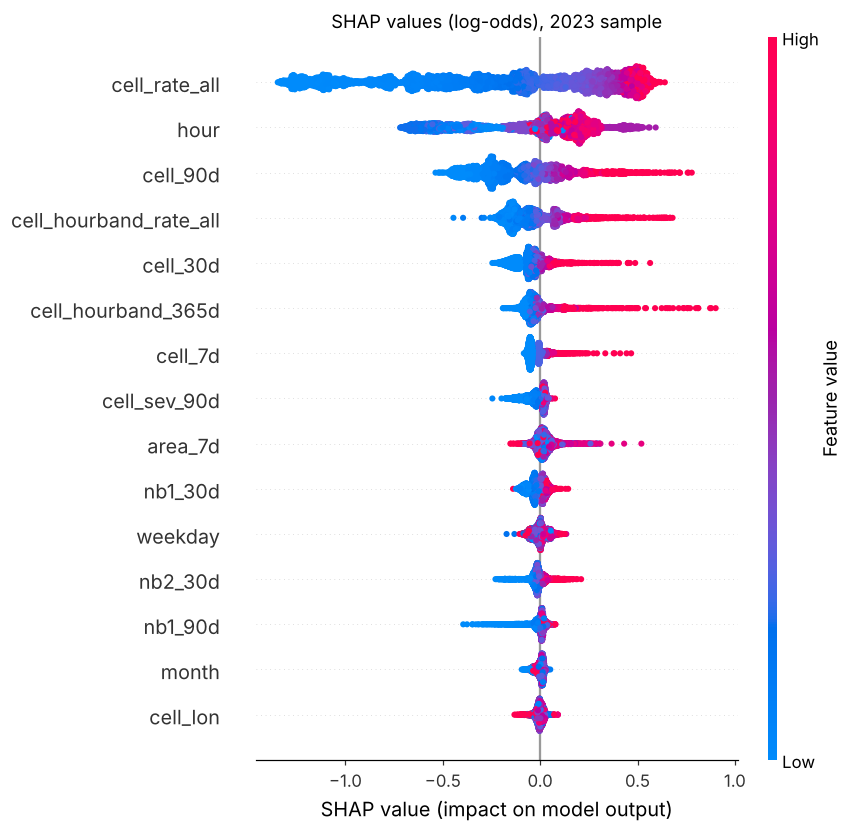

,mean |SHAP|
cell_rate_all,0.4669
hour,0.2466
cell_90d,0.1932
cell_hourband_rate_all,0.1189
cell_30d,0.0701
cell_hourband_365d,0.0572
cell_7d,0.0422
cell_sev_90d,0.0373
area_7d,0.0338
nb1_30d,0.0337


In [14]:
import shap
sample = test.sample(5000, weights="w", random_state=config.SEED)[FEATURES]  # weighted = looks like the real grid
contribs = model.get_booster().predict(xgb.DMatrix(sample), pred_contribs=True)[:, :-1]
shap.summary_plot(contribs, sample, max_display=15, show=False)
plt.title("SHAP values (log-odds), 2023 sample"); plt.show()
pd.Series(np.abs(contribs).mean(0), index=FEATURES).sort_values(ascending=False).head(10).rename("mean |SHAP|").to_frame().round(4)

## 5. Inference with the saved model

`score_cell` and `explain_cell` load the model saved by `python -m algorithm.models.train_xgb`
(`models/artifacts/xgb_risk.ubj`), which uses the same settings as above. These are the functions the Flask API calls.

- **risk** (0–1): percentile of this cell-hour among all USC-area cell-hours in 2023. Use it for colour and routing.
- **prob**: calibrated chance that at least one incident is reported in that cell in that hour.
- Cells inside the 10 miles with no LAPD data (Inglewood, Culver City, ...) return **None**: unknown, not safe.

In [15]:
from algorithm.scoring.score import score_cell, explain_cell, build_cache, cell_status

TODAY = dt.date(2026, 11, 14)
places = {
    "Tommy Trojan (USC)": (34.0206, -118.2854),
    "USC Village": (34.0254, -118.2851),
    "Figueroa & Adams": (34.0328, -118.2747),
    "DTLA, 7th St/Metro Center": (34.0486, -118.2587),
    "Hollywood & Highland": (34.1016, -118.3387),
    "Koreatown, Wilshire & Western": (34.0617, -118.3089),
    "Leimert Park": (34.0049, -118.3315),
    "Inglewood, SoFi Stadium": (33.9535, -118.3392),
}
HOURS = (2, 9, 14, 18, 22)
rows = []
for name, (lat, lng) in places.items():
    cell = h3.latlng_to_cell(lat, lng, config.H3_RES)
    rows.append({"place": name, "status": cell_status(cell), **{f"{h:02d}:00": score_cell(cell, h, TODAY) for h in HOURS}})
cols = [f"{h:02d}:00" for h in HOURS]
df = pd.DataFrame(rows).set_index("place")
df[cols] = df[cols].astype(float)
df.style.format("{:.2f}", subset=cols, na_rep="no data").background_gradient(cmap="YlOrRd", axis=None, vmin=0, vmax=1, subset=cols)

,status,02:00,09:00,14:00,18:00,22:00
place,,,,,,
Tommy Trojan (USC),ok,0.52,0.76,0.86,0.92,0.87
USC Village,ok,0.74,0.84,0.93,0.98,0.94
Figueroa & Adams,ok,0.54,0.58,0.69,0.77,0.76
"DTLA, 7th St/Metro Center",ok,1.00,1.00,1.00,1.00,1.00
Hollywood & Highland,ok,1.00,1.00,1.00,1.00,1.00
"Koreatown, Wilshire & Western",ok,0.99,0.96,0.99,1.00,1.00
Leimert Park,ok,0.68,0.74,0.86,0.89,0.91
"Inglewood, SoFi Stadium",no_data,no data,no data,no data,no data,no data


### Explain one score

`effect` is the SHAP contribution in log-odds: positive raises risk, negative lowers it.

In [16]:
cell = h3.latlng_to_cell(*places["Figueroa & Adams"], config.H3_RES)
ex = explain_cell(cell, 22, TODAY, top_k=6)
print(f"{ex['cell']} at {ex['hour']}:00 on {ex['date']}: risk {ex['risk']:.2f}, prob {ex['prob']:.2%} (history as of {ex['history_as_of']})")
pd.DataFrame(ex["factors"])[["label", "value", "effect"]]

8929a1d66abffff at 22:00 on 2026-11-14: risk 0.76, prob 0.62% (history as of 2023-12-31)


,label,value,effect
0,time of day,22.000,0.2213
1,long-run incident rate here,37.225,0.1204
2,"incidents here, last 90 days",7.000,-0.0827
3,long-run rate here at this hour,4.250,-0.0615
4,"incidents here, last 7 days",3.000,0.0490
5,day of week,5.000,0.0488


### What-if: override a feature

`context_features` lets the API pass live context, for example a phone that turned out to be nearer, or forcing darkness.

In [17]:
cell = h3.latlng_to_cell(*places["USC Village"], config.H3_RES)
pd.DataFrame({
    "as-is": [score_cell(cell, 17, TODAY)],
    "blue-light phone 50 m away": [score_cell(cell, 17, TODAY, {"dist_bluelight_m": 50})],
    "blue-light phone 1.5 km away": [score_cell(cell, 17, TODAY, {"dist_bluelight_m": 1500})],
    "is_dark forced on": [score_cell(cell, 17, TODAY, {"is_dark": 1})],
}, index=["USC Village, 5 PM"]).round(3)

,as-is,blue-light phone 50 m away,blue-light phone 1.5 km away,is_dark forced on
"USC Village, 5 PM",0.96,0.96,0.949,0.96


### The heatmap the app will show

`build_cache` scores every cell for all 24 hours in one call (about a second). This is what `scoring/cache/risk_cache.json` holds.

3,432 cells × 24 hours in 17.0s; 3,466 no-data cells


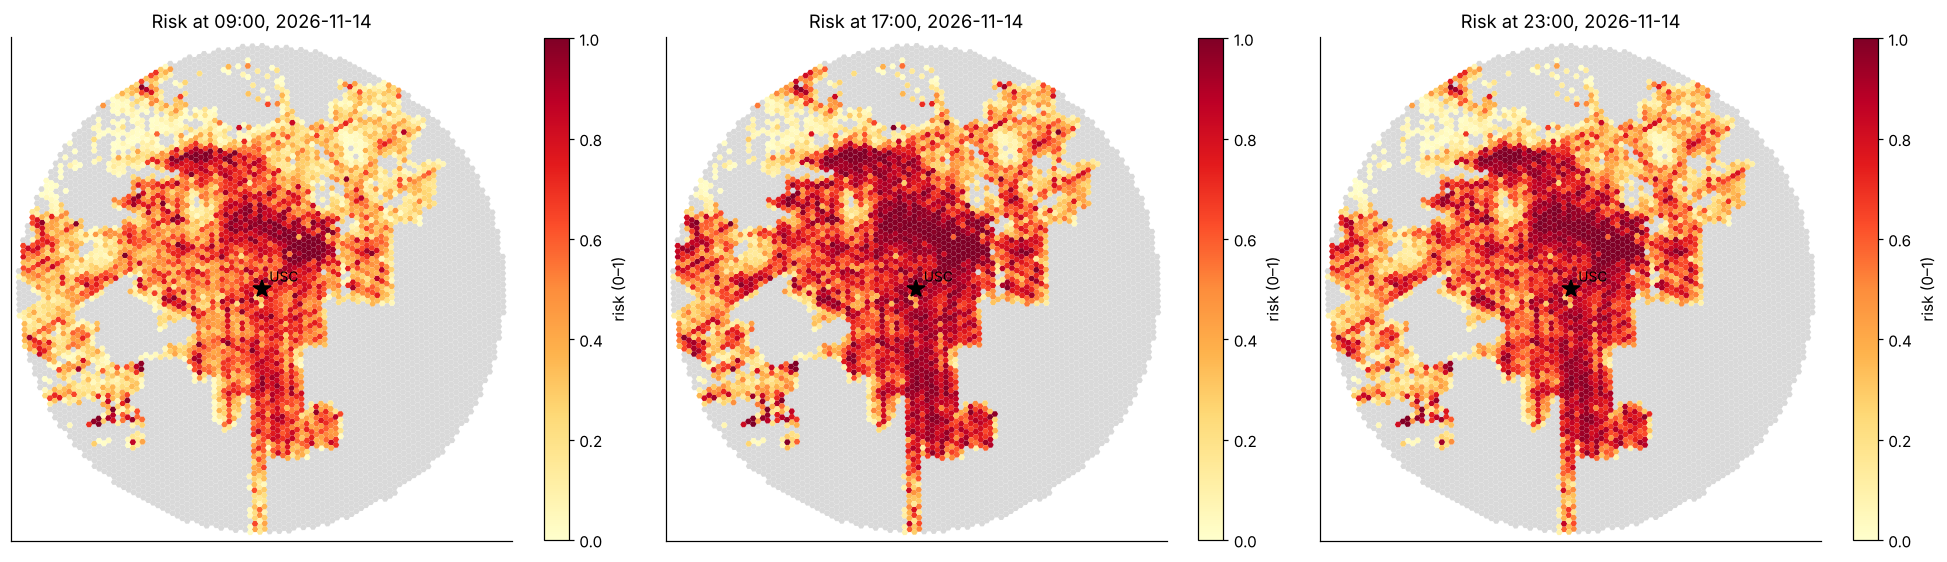

In [18]:
t0 = time.time()
cache = build_cache(TODAY)
print(f"{len(cache['cells']):,} cells × 24 hours in {time.time() - t0:.1f}s; {len(cache['no_data_cells']):,} no-data cells")
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, h in zip(axes, (9, 17, 23)):
    hexmap(ax, {c: v["risk"][h] for c, v in cache["cells"].items()}, f"Risk at {h:02d}:00, {TODAY}",
           vmin=0, vmax=1, label="risk (0–1)", no_data=cache["no_data_cells"])
plt.tight_layout(); plt.show()

## Caveats

- LAPD data shows what gets **reported and policed**, not where harm actually happens. Show the factors behind each score (`explain_cell`), and use risk as a cost on routes, not a hard block.
- Blue-light phone locations are **placeholders** until we load the real USC DPS coordinates into `data/bluelight_phones.csv`.
- For dates after 2023, history features are anchored at the end of 2023 (the last full year before the NIBRS reporting drop).
- Grey cells (inside 10 miles, no LAPD data) are other police jurisdictions. LASD publishes data for county areas but its historical files stop at 2021, so they are not included yet.